### Get data

In [1]:
import numpy as np
import pandas as pd

#### Rod

In [2]:
real_l = 1.049
real_sigma_l = 0.1

buchi_1 = [(real_l/2 - 0.1*x)*100 for x in range(1,6)]
buchi_2 = [(real_l/2 -0.05 - 0.1*x)*100 for x in range(5)]
d = np.array(buchi_2 + buchi_1[::-1])
d = d/100

distance from center of mass of each point  
first point is the one strating from the end labeled A  

In [3]:
d

array([0.4745, 0.3745, 0.2745, 0.1745, 0.0745, 0.0245, 0.1245, 0.2245,
       0.3245, 0.4245])

In [4]:
sigma_d = np.full(d.shape, 0.01)  # taken from tool resolution

#### Period

In [5]:
T_full = np.array([[16.35, 16.15, 16.27, 16.34, 16.16],
              [15.72, 15.71, 15.62, 15.64, 15.69],
              [15.55, 15.48, 15.53, 15.59, 15.67],
              [16.87, 16.44, 16.68, 16.54, 16.84],
              [22.81, 22.59, 22.59, 22.70, 22.76],
              [38.23, 38.82, 38.73, 38.99, 38.83],
              [18.57, 18.83, 18.67, 18.90, 18.79],
              [15.93, 15.76, 15.87, 15.94, 15.72],
              [15.73, 15.54, 15.47, 15.57, 15.65],
              [16.03, 15.97, 16.13, 16.19, 16.03]
              ])  


# each row are all measurements with a specific length d
# each row, not each col

### Data analysis

better

In [9]:
T = np.mean(T_full, axis=1)/10
sigma_T = np.std(T_full/10, ddof=1, axis=1)

In [11]:
for x in range(len(T_full)):
    print(f'd: {d[x]:.2f}, T = {T[x]:.2f} + {sigma_T[x]:.2f}')

d: 0.47, T = 1.63 + 0.01
d: 0.37, T = 1.57 + 0.00
d: 0.27, T = 1.56 + 0.01
d: 0.17, T = 1.67 + 0.02
d: 0.07, T = 2.27 + 0.01
d: 0.02, T = 3.87 + 0.03
d: 0.12, T = 1.88 + 0.01
d: 0.22, T = 1.58 + 0.01
d: 0.32, T = 1.56 + 0.01
d: 0.42, T = 1.61 + 0.01


### Plot

i have:   

d  
sigma_d  
T  
sigma_T  

In [13]:
def period_model(d, l):
    return 2.0 * np.pi * np.sqrt((l**2.0 / 12.0 + d**2.0) / (9.81 * d))

fitted l = 1.0398397092506924 + 0.002659139497357292


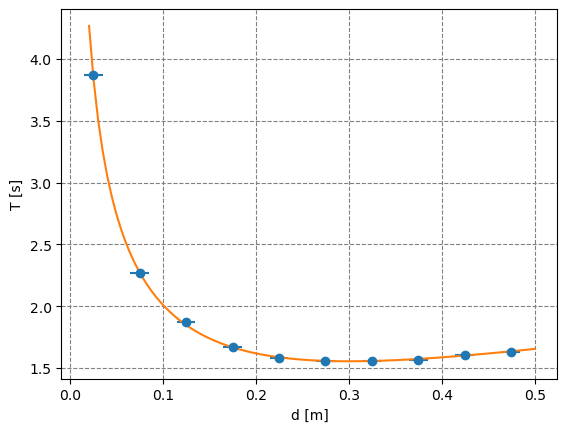

In [14]:
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit


plt.figure('Periodo')
plt.errorbar(d, T, sigma_T, sigma_d, fmt='o')

popt, pcov = curve_fit(period_model, d, T, sigma=sigma_T)
l_hat = popt[0]
sigma_l = np.sqrt(pcov[0, 0])

print(f'fitted l = {l_hat} + {sigma_l}')


x = np.linspace(0.02, 0.5, 100)
plt.plot(x, period_model(x, l_hat))
plt.xlabel('d [m]')
plt.ylabel('T [s]')
plt.grid(which='both', ls='dashed', color='gray')

plt.show()

### Notes

obiettivo, vedere se l che viene dalla formula conicide con quello vero  

compatibilità

$ | \hat{a} - \hat{b} | \le n\sqrt{\sigma^2_a+ \sigma^2_b }$  


In [14]:
left = abs(1.05-1.040)

In [15]:
import math
right= math.sqrt(0.01**2 + 0.003**2)

In [16]:
print(left, right)

0.010000000000000009 0.01044030650891055
